# Asset Swap Spreads (Par-Par, Proceeds, Z-Spread) vs Benchmark

A development bank's treasury borrows at SOFR plus a small spread, so a bond is only worth buying if it pays more than that once its fixed coupons are swapped into floating. That extra is the asset swap spread. This notebook computes it bond by bond for a realistic treasury portfolio and flags which bonds look rich or cheap.

**What it does.** It measures how much each bond in an MDB-style treasury portfolio pays over SOFR once it is asset-swapped, and flags which bonds are rich or cheap against their peers and against market benchmarks.

**Data.** Live bond-level holdings of four iShares ETFs (Treasuries, agencies, sub-sovereigns, banks, corporates), the Treasury par curve (U.S. Treasury), and ICE BofA investment-grade OAS indices (FRED).

**Methods.** Cash-flow pricing on a SOFR discount curve, three spread measures (par-par asset swap, proceeds asset swap, Z-spread) plus the I-spread, and a robust relative-value regression of spread on sector and duration.

**Key output.** A bond-by-bond spread table, the richest and cheapest bonds, sleeve averages against the IG benchmark and its 10-year history, and a relative-value dashboard.

## 1. Why asset swap spreads

An MDB treasury does not judge a bond by its yield. It funds at **SOFR + a spread**, so what matters is what the bond pays **over SOFR** once its fixed coupons are swapped into floating. That number is the **asset swap spread (ASW)**. It drives:

- **Investment decisions.** A bond only adds value if its ASW beats the bank's funding spread.
- **Relative value.** Two bonds with the same rating and duration should have similar ASWs; a large gap is either an opportunity or a warning.
- **Risk reporting.** Spread duration and CS01 are measured on these spreads.

There is more than one way to define "the spread over swaps", and they differ precisely when a bond trades away from par. This notebook computes all of them side by side.

## 2. Four spread measures

Let $P$ be the bond's dirty market price per 100 face, $P^{\text{swap}}$ its price when every cash flow is discounted on the SOFR curve, and $A$ the PV of a 1 bp annual running spread paid on the bond's coupon dates (the *annuity*):

| Measure | Definition | Intuition |
|---|---|---|
| **Par-par ASW** | $\displaystyle \text{ASW}_{pp}=\frac{P^{\text{swap}}-P}{A}$ | Investor pays par for the package (bond + swap). The market standard. |
| **Proceeds ASW** | $\displaystyle \text{ASW}_{pr}=\frac{P^{\text{swap}}-P}{A\cdot P/100}$ | Swap notional equals the money actually paid; differs from par-par when $P\neq100$. |
| **Z-spread** | $s$ such that $\sum_j CF_j\,DF^{\text{SOFR}}(t_j)\,e^{-s\,t_j}=P$ | A constant shift of the discount curve. Insensitive to how the swap is structured. |
| **I-spread** | yield to maturity − SOFR par swap rate at the bond's maturity | Quick screen, ignores curve shape. |

A **positive** spread means the bond pays more than SOFR, so it is cheap to swaps. A negative spread means it trades rich. Tax-exempt munis are the classic example: their yields are low because US taxable investors value the exemption.

## 3. Setup

In [1]:
# --- Standard library
import datetime as dt
import io
import os
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import QuantLib as ql
import requests
import statsmodels.formula.api as smf
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from scipy.optimize import brentq

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# --- Portfolio design: MDB-style allocation
PORTFOLIO_SIZE_USD = 1_000_000_000
SLEEVE_TARGETS = {
    "US Treasuries": 0.40,
    "Agencies": 0.20,
    "Sub-sovereigns": 0.10,
    "Banks": 0.15,
    "Corporates": 0.15,
}
BONDS_PER_SLEEVE = 30
MATURITY_RANGE_Y = (1.0, 30.0)

# SOFR OIS minus Treasury par (bp): an explicit, documented assumption.
# Swap spreads observed from reported trades can replace this dict to remove
# the assumption.
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}

print(f"QuantLib {ql.__version__} · run on {dt.date.today():%Y-%m-%d}")

QuantLib 1.44 · run on 2026-10-18


In [2]:
# --- Caching helper
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SLEEVE_COLORS = dict(zip(SLEEVE_TARGETS, PALETTE))
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 4. Data

### 4.1 Bonds: iShares holdings

The sleeves follow an MDB-style allocation. The notebook downloads its own data so it stays self-contained.

| Sleeve | ETF (product id) |
|---|---|
| US Treasuries | GOVT (239468) |
| Agencies | AGZ (239457) |
| Sub-sovereigns | MUB (239766) |
| Banks / Corporates | IGIB (239463), split by sector |

Source pattern: `https://www.ishares.com/us/products/<id>/fund/latest-holdings.csv`.

In [3]:
ISHARES_FUNDS = {
    "GOVT": "239468",
    "AGZ": "239457",
    "MUB": "239766",
    "IGIB": "239463",
}


def fetch_holdings(ticker):
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=30
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    table = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    table["fund"], table["as_of"] = ticker, as_of
    return table


raw = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)
num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", "", regex=False).str.strip(),
    errors="coerce",
)
col = lambda name, default="": (
    raw[name] if name in raw else pd.Series(default, index=raw.index)
)

bonds = pd.DataFrame({
    "fund": raw["fund"],
    "name": raw["Name"],
    "isin": col("ISIN"),
    "sector": col("Sector").fillna(""),
    "asset_class": col("Asset Class").fillna(""),
    "currency": col("Currency", "USD").fillna(""),
    "weight_pct": num(raw["Weight (%)"]),
    "clean_price": num(col("Price", np.nan)),
    "coupon_pct": num(raw["Coupon (%)"]),
    "ishares_ytm_pct": num(col("YTM (%)", np.nan)),
    "maturity": pd.to_datetime(
        raw["Maturity"], format="%b %d, %Y", errors="coerce"
    ).fillna(pd.to_datetime(raw["Maturity"], format="mixed", errors="coerce")),
})
SLEEVE_BY_FUND = {
    "GOVT": "US Treasuries",
    "AGZ": "Agencies",
    "MUB": "Sub-sovereigns",
}
bonds["sleeve"] = [
    SLEEVE_BY_FUND.get(f)
    or ("Banks" if re.search("bank", s, re.I) else "Corporates")
    for f, s in zip(bonds["fund"], bonds["sector"])
]


def clean_price_from_ytm(coupon_pct, ytm_pct, maturity, settle):
    """
    Clean price per 100 from a semi-annual yield, used when a holdings file has
    no Price column.
    """
    if (
        any(pd.isna(v) for v in (coupon_pct, ytm_pct, maturity))
        or maturity <= settle
    ):
        return np.nan
    c, y = coupon_pct / 2, ytm_pct / 200
    # coupon dates, walking back from maturity
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfs = dates[-1], sorted(dates[:-1])
    # fraction of the first period still to run
    frac = (cfs[0] - settle).days / (cfs[0] - prev).days
    dirty = sum(c / (1 + y) ** (frac + k) for k in range(len(cfs))) + 100 / (
        1 + y
    ) ** (frac + len(cfs) - 1)
    # remove accrued interest
    return dirty - c * (1 - frac)


missing_price = bonds["clean_price"].isna() & bonds["ishares_ytm_pct"].notna()
settle = pd.to_datetime(raw["as_of"], format="%b %d, %Y", errors="coerce")
bonds.loc[missing_price, "clean_price"] = [
    clean_price_from_ytm(c, y, m, s)
    for c, y, m, s in zip(
        bonds.loc[missing_price, "coupon_pct"],
        bonds.loc[missing_price, "ishares_ytm_pct"],
        bonds.loc[missing_price, "maturity"],
        settle[missing_price],
    )
]
if missing_price.any():
    print(
        "Clean price rebuilt from iShares YTM for"
        f" {missing_price.sum()} holdings"
        f" ({', '.join(bonds.loc[missing_price, 'fund'].unique())}: file has"
        " no Price column)"
    )
print(f"{len(bonds):,} holdings parsed")

Clean price rebuilt from iShares YTM for 119 holdings (AGZ: file has no Price column)
10,942 holdings parsed


### 4.2 Curves and benchmarks

- **Treasury par curve** (U.S. Treasury) → Treasury zero curve; the SOFR curve is Treasury zero + swap spread.
- **ICE BofA option-adjusted spreads** (FRED), the market benchmark for credit:
  - `BAMLC0A0CM`: US Corporate IG index;
  - `BAMLC0A2CAA`, `BAMLC0A3CA`, `BAMLC0A4CBBB`: the AA, A and BBB buckets.

In [4]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw_t = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw_t.empty:
        raw_t = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw_t["date"] = pd.to_datetime(raw_t["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw_t.columns
        if tenor_in_years(c) is not None
    }
    long = raw_t.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

fred = Fred(api_key=FRED_API_KEY)
OAS_SERIES = {
    "BAMLC0A0CM": "IG index",
    "BAMLC0A2CAA": "AA",
    "BAMLC0A3CA": "A",
    "BAMLC0A4CBBB": "BBB",
}


def fetch_oas():
    frames = [
        pd.DataFrame({"date": s.index, "series": name, "oas_pct": s.values})
        for sid, name in OAS_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3653)
            ).dropna()
        ]
    ]
    return pd.concat(frames, ignore_index=True)


oas = (
    cached("fred_ice_bofa_oas", fetch_oas)
    .pivot(index="date", columns="series", values="oas_pct")
    .sort_index()
)
print(
    f"Evaluation date {EVAL_DATE:%Y-%m-%d} · IG OAS today"
    f" {oas['IG index'].dropna().iloc[-1]*100:.0f} bp"
)

Evaluation date 2026-10-16 · IG OAS today 84 bp


## 5. Portfolio and curves

The largest fixed-coupon USD bonds maturing in 1–30 years from each fund, re-weighted to the sleeve targets.

In [5]:
today = EVAL_DATE.normalize()
bonds["years_to_maturity"] = (bonds["maturity"] - today).dt.days / 365.25
eligible = bonds[
    bonds["currency"].eq("USD")
    & bonds["clean_price"].gt(0)
    & bonds["coupon_pct"].notna()
    & bonds["years_to_maturity"].between(*MATURITY_RANGE_Y)
    & ~bonds["asset_class"].str.contains(
        "Cash|Money Market|Futures", case=False
    )
]
portfolio = (
    eligible.sort_values("weight_pct", ascending=False)
    .groupby("sleeve", group_keys=False)
    .head(BONDS_PER_SLEEVE)
    .reset_index(drop=True)
)
portfolio["market_value"] = (
    portfolio.groupby("sleeve")["weight_pct"].transform(lambda w: w / w.sum())
    * portfolio["sleeve"].map(SLEEVE_TARGETS)
    * PORTFOLIO_SIZE_USD
)

# --- Treasury zero curve (QuantLib), sampled on a fine grid
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

GRID_T = np.linspace(1 / 365, 31, 31 * 52)
GRID_Z_UST = np.array(
    [ust_curve.zeroRate(float(t), ql.Continuous).rate() for t in GRID_T]
)
spread_t = np.array(list(SWAP_SPREAD_BP), dtype=float)
spread_v = np.array(list(SWAP_SPREAD_BP.values())) / 1e4

ust_zero = lambda t: np.interp(t, GRID_T, GRID_Z_UST)
# SOFR = Treasury + swap spread
sofr_zero = lambda t: ust_zero(t) + np.interp(t, spread_t, spread_v)
sofr_df = lambda t: np.exp(-sofr_zero(t) * t)


def sofr_par_swap_rate(T):
    """
    Annual-pay SOFR par swap rate for maturity T (fractional maturities use a
    stub).
    """
    pay = np.arange(T, 0, -1.0)[::-1]
    accr = np.diff(np.concatenate([[0.0], pay]))
    return (1 - sofr_df(T)) / np.sum(accr * sofr_df(pay))


print(
    f"{len(portfolio)} bonds · SOFR par swap 10Y"
    f" {sofr_par_swap_rate(10)*100:.2f}% · Treasury zero 10Y"
    f" {ust_zero(10)*100:.2f}%"
)

150 bonds · SOFR par swap 10Y 4.76% · Treasury zero 10Y 5.06%


## 6. Spread measures, bond by bond

For each bond we build its semi-annual cash flows, compute the dirty price, and derive all four measures. The yield to maturity is solved from the dirty price (semi-annual compounding) for the I-spread.

In [6]:
def cash_flows(cpn, T):
    times = np.arange(T, 0, -0.5)[::-1]
    amounts = np.full(len(times), cpn / 2)
    amounts[-1] += 100
    return times, amounts


def solve(f, lo, hi):
    try:
        return brentq(f, lo, hi)
    except ValueError:
        return np.nan


rows = []
for _, b in portfolio.iterrows():
    t, cf = cash_flows(b["coupon_pct"], b["years_to_maturity"])
    accrued = b["coupon_pct"] / 2 * (1 - t[0] / 0.5)
    dirty = b["clean_price"] + accrued

    # bond priced on the SOFR curve
    p_swap = np.sum(cf * sofr_df(t))
    # accrual of each coupon period
    accr = np.diff(np.concatenate([[0.0], t]))
    # PV of 1 bp running on 100 face
    annuity = np.sum(accr * sofr_df(t)) * 100 / 1e4

    z_sofr = solve(
        lambda s: np.sum(cf * sofr_df(t) * np.exp(-s * t)) - dirty, -0.10, 0.30
    )
    z_ust = solve(
        lambda s: np.sum(cf * np.exp(-(ust_zero(t) + s) * t)) - dirty,
        -0.10,
        0.30,
    )
    ytm = solve(
        lambda y: np.sum(cf / (1 + y / 2) ** (2 * t)) - dirty, -0.05, 0.50
    )

    rows.append({
        "dirty_price": dirty,
        "asw_par_par_bp": (p_swap - dirty) / annuity,
        "asw_proceeds_bp": (p_swap - dirty) / (annuity * dirty / 100),
        "z_spread_sofr_bp": z_sofr * 1e4,
        "z_spread_ust_bp": z_ust * 1e4,
        "ytm_pct": ytm * 100,
        "i_spread_bp": (
            ytm - sofr_par_swap_rate(b["years_to_maturity"])
        ) * 1e4,
    })

spreads = pd.concat([portfolio, pd.DataFrame(rows)], axis=1).dropna(
    subset=["asw_par_par_bp", "z_spread_sofr_bp"]
)
measures = [
    "asw_par_par_bp",
    "asw_proceeds_bp",
    "z_spread_sofr_bp",
    "i_spread_bp",
]
sleeve_avg = (
    spreads.groupby("sleeve")[measures + ["z_spread_ust_bp"]]
    .median()
    .reindex(SLEEVE_TARGETS)
)
sleeve_avg

,asw_par_par_bp,asw_proceeds_bp,z_spread_sofr_bp,i_spread_bp,z_spread_ust_bp
sleeve,,,,,
US Treasuries,25.61,26.05,25.49,22.44,3.85
Agencies,31.35,31.55,30.24,26.62,9.17
Sub-sovereigns,4.63,4.39,4.41,-0.93,-48.72
Banks,115.80,117.76,116.29,113.82,82.55
Corporates,112.62,118.75,115.21,112.80,80.72


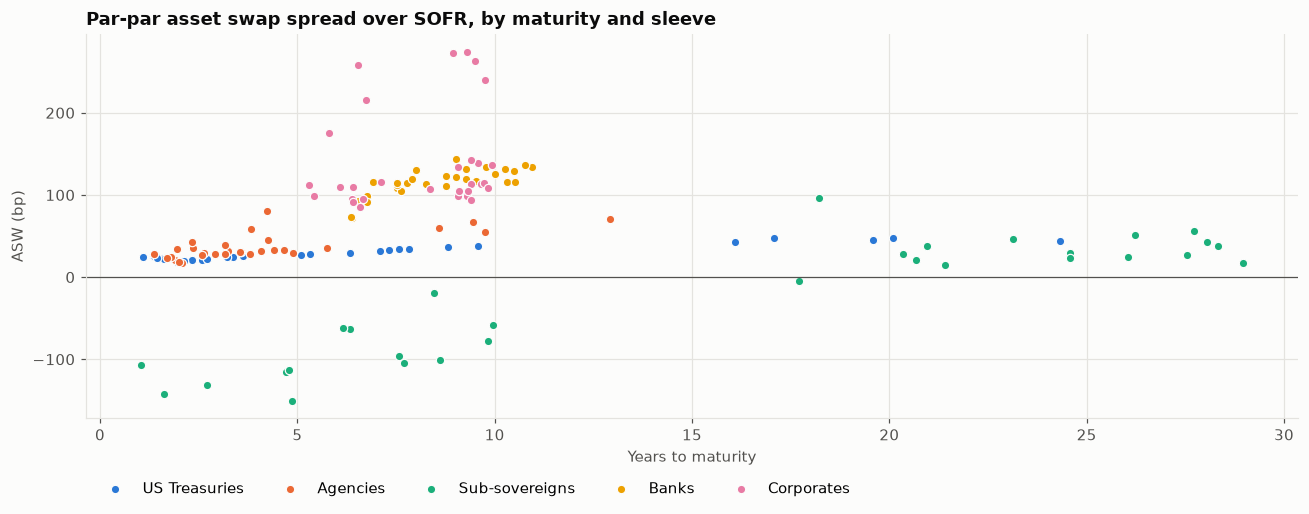

In [7]:
# --- Chart 1: par-par ASW vs maturity, by sleeve
fig, ax = plt.subplots(figsize=(12, 4.8))
for sleeve in SLEEVE_TARGETS:
    g = spreads[spreads["sleeve"] == sleeve]
    ax.scatter(
        g["years_to_maturity"],
        g["asw_par_par_bp"],
        s=30,
        color=SLEEVE_COLORS[sleeve],
        edgecolor=SURFACE,
        linewidth=0.8,
        label=sleeve,
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Par-par asset swap spread over SOFR, by maturity and sleeve")
ax.set_xlabel("Years to maturity")
ax.set_ylabel("ASW (bp)")
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, -0.13))
plt.tight_layout()
save_fig(fig, "01_asw_vs_maturity")
plt.show()

### 6.1 When do the measures disagree?

Par-par and proceeds ASW are identical for a bond priced at par. For a bond at a premium, par-par puts the premium into the swap and proceeds spreads it over a larger notional, so the two diverge. The chart makes the price effect visible, which is exactly the point a risk reviewer checks when two desks report different spreads for the same bond.

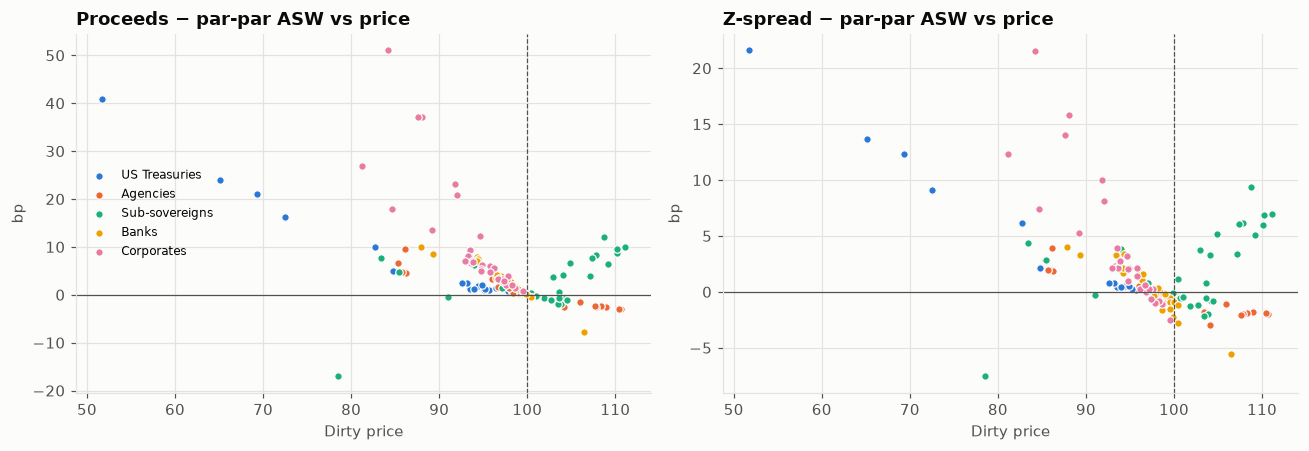

In [8]:
spreads["proceeds_minus_parpar_bp"] = (
    spreads["asw_proceeds_bp"] - spreads["asw_par_par_bp"]
)
spreads["z_minus_parpar_bp"] = (
    spreads["z_spread_sofr_bp"] - spreads["asw_par_par_bp"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, colname, title in [
    (axes[0], "proceeds_minus_parpar_bp", "Proceeds − par-par ASW vs price"),
    (axes[1], "z_minus_parpar_bp", "Z-spread − par-par ASW vs price"),
]:
    for sleeve in SLEEVE_TARGETS:
        g = spreads[spreads["sleeve"] == sleeve]
        ax.scatter(
            g["dirty_price"],
            g[colname],
            s=24,
            color=SLEEVE_COLORS[sleeve],
            edgecolor=SURFACE,
            linewidth=0.8,
            label=sleeve,
        )
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.axvline(100, color=INK_2, lw=0.8, ls="--")
    ax.set_title(title)
    ax.set_xlabel("Dirty price")
    ax.set_ylabel("bp")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_measure_differences_vs_price")
plt.show()

## 7. Relative value: rich or cheap against peers?

The par-par ASW of each bond is regressed on its sleeve and on duration, with a quadratic term so the spread curve can bend:

$$
\text{ASW}_i = \alpha_{\text{sleeve}(i)} + \beta_1 D_i + \beta_2 D_i^2 + \varepsilon_i .
$$

The fit uses robust (Huber) regression, so a few distressed or mispriced bonds cannot tilt the curve. The residual $\varepsilon_i$ is the bond's spread **relative to similar bonds**: positive = cheap (pays more than peers), negative = rich.

In [9]:
# smooth, monotone in maturity
spreads["duration_proxy"] = spreads["years_to_maturity"].clip(upper=30) ** 0.85
model = smf.rlm(
    "asw_par_par_bp ~ C(sleeve) + duration_proxy + I(duration_proxy**2)",
    data=spreads,
).fit()
spreads["fair_asw_bp"] = model.fittedvalues
spreads["rv_residual_bp"] = spreads["asw_par_par_bp"] - spreads["fair_asw_bp"]

print(model.summary().tables[1])
cheapest = spreads.nlargest(10, "rv_residual_bp")
richest = spreads.nsmallest(10, "rv_residual_bp")
show = [
    "sleeve",
    "name",
    "maturity",
    "coupon_pct",
    "clean_price",
    "asw_par_par_bp",
    "fair_asw_bp",
    "rv_residual_bp",
]
cheapest[show]

                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      22.0031      5.042      4.364      0.000      12.120      31.886
C(sleeve)[T.Banks]             62.6377      5.012     12.497      0.000      52.814      72.462
C(sleeve)[T.Corporates]        64.4840      4.935     13.066      0.000      54.811      74.157
C(sleeve)[T.Sub-sovereigns]  -124.2137      5.222    -23.788      0.000    -134.448    -113.979
C(sleeve)[T.US Treasuries]    -12.9297      4.362     -2.964      0.003     -21.479      -4.380
duration_proxy                  2.8749      1.597      1.800      0.072      -0.255       6.005
I(duration_proxy ** 2)          0.3467      0.090      3.840      0.000       0.170       0.524


,sleeve,name,maturity,coupon_pct,clean_price,asw_par_par_bp,fair_asw_bp,rv_residual_bp
79,Corporates,ORACLE CORPORATION,2036-02-04,5.70,86.96,274.53,121.00,153.53
122,Corporates,ORACLE CORPORATION,2035-09-26,5.20,83.93,272.25,119.38,152.88
124,Corporates,ORACLE CORPORATION,2033-05-04,5.35,89.38,257.66,109.15,148.51
90,Corporates,QTS FAYETTEVILLE I DC1-2 LLC 144A,2036-04-15,5.70,87.62,262.99,121.89,141.10
65,Corporates,SPACE EXPLORATION TECHNOLOGIES COR 144A,2036-07-15,5.88,90.54,239.72,123.04,116.68
146,Sub-sovereigns,CHICAGO ILL,2045-01-01,5.25,92.48,96.29,-20.18,116.47
70,Corporates,SPACE EXPLORATION TECHNOLOGIES COR 144A,2033-07-15,5.65,93.20,215.85,109.95,105.90
121,Corporates,CARNIVAL CORPORATION LTD 144A,2032-08-01,5.75,96.66,175.77,106.15,69.61
142,Sub-sovereigns,DISTRICT COLUMBIA UNIV REV,2035-04-03,5.00,103.46,-19.01,-71.47,52.46
24,Agencies,FEDERAL HOME LOAN MORTGAGE CORPORA MTN,2031-01-09,4.10,94.91,80.27,35.83,44.44


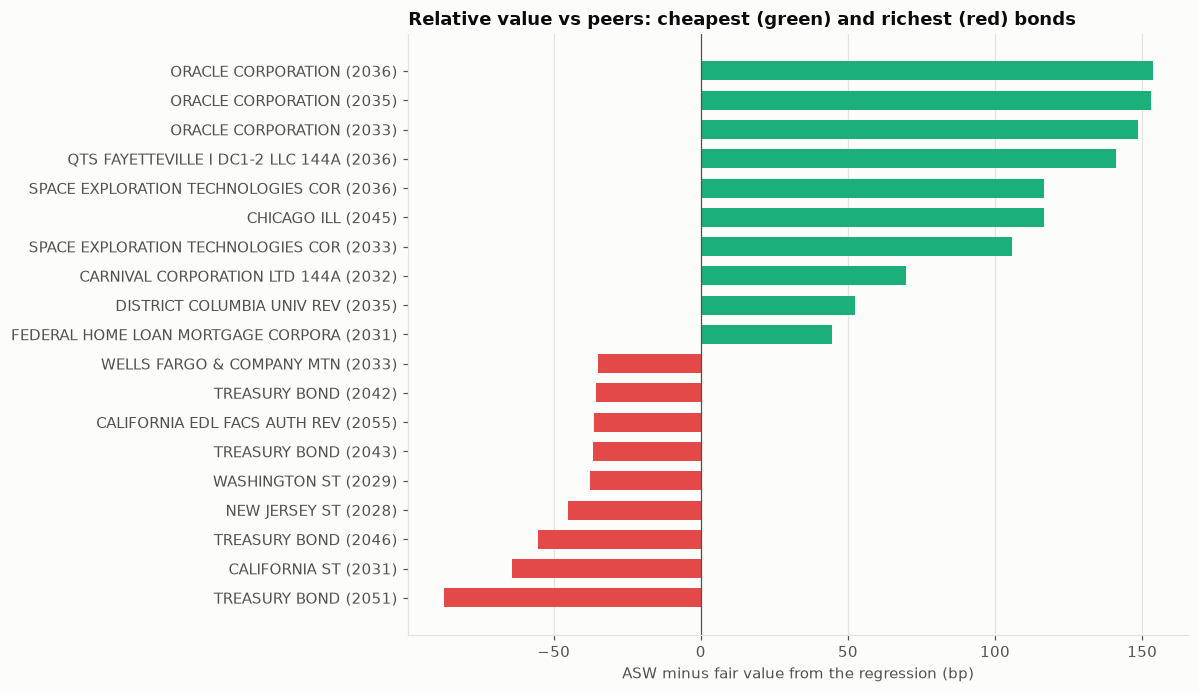

In [10]:
# --- Chart 3: the 10 cheapest and 10 richest bonds
top = pd.concat([richest, cheapest]).sort_values("rv_residual_bp")
labels = [f"{n[:34]} ({m:%Y})" for n, m in zip(top["name"], top["maturity"])]
fig, ax = plt.subplots(figsize=(11, 6.4))
ax.barh(
    labels,
    top["rv_residual_bp"],
    color=[PALETTE[2] if v > 0 else PALETTE[7] for v in top["rv_residual_bp"]],
    height=0.65,
)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title(
    "Relative value vs peers: cheapest (green) and richest (red) bonds"
)
ax.set_xlabel("ASW minus fair value from the regression (bp)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "03_rich_cheap")
plt.show()

## 8. Against the market: the IG benchmark and its history

Our bank and corporate bonds are compared with the ICE BofA US Corporate IG index. Both spreads are measured over Treasuries, so they are directly comparable. The 10-year history shows whether credit as a whole is cheap or rich today, which is the first question an investment committee asks.

IG OAS today 84 bp, higher than 47% of the last 10 years


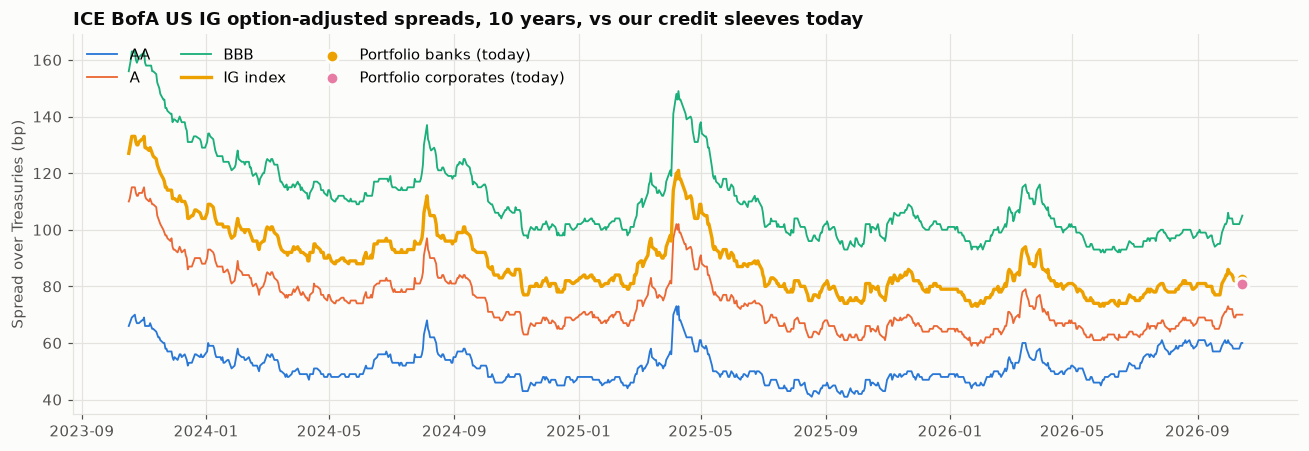

,portfolio median Z-spread over UST (bp),ICE BofA IG OAS (bp),difference (bp)
sleeve,,,
Banks,82.50,84.00,-1.50
Corporates,80.70,84.00,-3.30


In [11]:
ig = oas["IG index"].dropna() * 100  # bp
ig_now, ig_pct = ig.iloc[-1], (ig < ig.iloc[-1]).mean() * 100
credit = spreads[spreads["sleeve"].isin(["Banks", "Corporates"])]
benchmark = pd.DataFrame({
    "portfolio median Z-spread over UST (bp)": credit.groupby("sleeve")[
        "z_spread_ust_bp"
    ].median(),
    "ICE BofA IG OAS (bp)": ig_now,
})
benchmark["difference (bp)"] = benchmark.iloc[:, 0] - benchmark.iloc[:, 1]
print(
    f"IG OAS today {ig_now:.0f} bp, higher than {ig_pct:.0f}% of the last 10"
    " years"
)

fig, ax = plt.subplots(figsize=(12, 4.2))
for i, name in enumerate(["AA", "A", "BBB", "IG index"]):
    if name in oas:
        s = oas[name].dropna() * 100
        ax.plot(
            s.index,
            s.values,
            color=PALETTE[i],
            lw=2.2 if name == "IG index" else 1.2,
            label=name,
        )
for sleeve in ["Banks", "Corporates"]:
    if sleeve in benchmark.index:
        ax.scatter(
            [ig.index[-1]],
            [benchmark.loc[sleeve].iloc[0]],
            s=70,
            zorder=3,
            color=SLEEVE_COLORS[sleeve],
            edgecolor=SURFACE,
            linewidth=2,
            label=f"Portfolio {sleeve.lower()} (today)",
        )
ax.set_title(
    "ICE BofA US IG option-adjusted spreads, 10 years, vs our credit sleeves"
    " today"
)
ax.set_ylabel("Spread over Treasuries (bp)")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()
save_fig(fig, "04_benchmark_history")
plt.show()
benchmark.round(1)

## 9. Relative-value dashboard

In [12]:
weighted = lambda g, c: np.average(g[c], weights=g["market_value"])
port_asw = weighted(spreads, "asw_par_par_bp")

dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.12,
    horizontal_spacing=0.09,
    row_heights=[0.45, 0.55],
    specs=[[{}, {}], [{"type": "table"}, {"type": "table"}]],
    subplot_titles=(
        "Par-par ASW vs maturity (bp)",
        "Median spread by sleeve and measure (bp)",
        "Cheapest 10 vs peers",
        "Richest 10 vs peers",
    ),
)
for sleeve in SLEEVE_TARGETS:
    g = spreads[spreads["sleeve"] == sleeve]
    dash.add_trace(
        go.Scatter(
            x=g["years_to_maturity"],
            y=g["asw_par_par_bp"],
            mode="markers",
            name=sleeve,
            text=g["name"],
            marker=dict(
                color=SLEEVE_COLORS[sleeve],
                size=7,
                line=dict(color=SURFACE, width=1),
            ),
        ),
        1,
        1,
    )
for i, (m, label) in enumerate([
    ("asw_par_par_bp", "Par-par"),
    ("asw_proceeds_bp", "Proceeds"),
    ("z_spread_sofr_bp", "Z-spread"),
    ("i_spread_bp", "I-spread"),
]):
    dash.add_trace(
        go.Bar(
            x=sleeve_avg.index,
            y=sleeve_avg[m],
            name=label,
            marker_color=PALETTE[i],
            legendgroup="m",
            showlegend=True,
        ),
        1,
        2,
    )


def rv_table(df):
    return go.Table(
        header=dict(
            values=["Bond", "Sleeve", "ASW", "Fair", "RV (bp)"],
            fill_color="#f1f0ec",
            font=dict(color=INK, size=11),
            align="left",
        ),
        cells=dict(
            values=[
                [n[:28] for n in df["name"]],
                df["sleeve"],
                df["asw_par_par_bp"].round(1),
                df["fair_asw_bp"].round(1),
                df["rv_residual_bp"].round(1),
            ],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=10),
            align="left",
            height=24,
        ),
        columnwidth=[2.6, 1.4, 0.8, 0.8, 0.9],
    )


dash.add_trace(rv_table(cheapest), 2, 1)
dash.add_trace(rv_table(richest), 2, 2)
dash.update_yaxes(
    range=[
        min(0, sleeve_avg.min().min()) * 1.15 - 5,
        sleeve_avg.max().max() * 1.15,
    ],
    row=1,
    col=2,
)
dash.update_layout(
    barmode="group",
    height=1050,
    width=1350,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    # one legend row under the charts
    legend=dict(orientation="h", y=-0.03, x=0, yanchor="top"),
    margin=dict(t=120, b=70),
    title=dict(
        x=0.01,
        text=(
            f"<b>Asset swap relative value · {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>Portfolio MV-weighted"
            f" par-par ASW {port_asw:+.0f} bp over SOFR · IG OAS"
            f" {ig_now:.0f} bp ({ig_pct:.0f}th percentile of 10Y)</span>"
        ),
    ),
)
dash.write_html(OUT_DIR / "dashboard.html", include_plotlyjs="cdn")
try:
    dash.write_image(OUT_DIR / "dashboard.png", scale=2)
    print("Dashboard saved: outputs/dashboard.html and .png")
except Exception as err:
    print(
        f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
        " `plotly_get_chrome` once."
    )
spreads.drop(columns=["duration_proxy"]).to_csv(
    OUT_DIR / "bond_spreads.csv", index=False
)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**What to look for**

- **Treasuries pay a small positive spread over SOFR.** This is the mirror image of negative swap spreads: since 2023, SOFR swap rates have sat *below* Treasury yields, so an asset-swapped Treasury earns SOFR plus a positive spread (roughly 20–30 bp in late 2026, wider at the long end).
- **Munis trade rich**: well below Treasuries (a negative Z-spread over UST) and, at the short end, below SOFR as well, because their income is tax-exempt for US investors. For an MDB that pays no tax, that exemption is worth nothing, a useful and non-obvious screening conclusion.
- **Agencies trade a few basis points over Treasuries**, as near-sovereign credits usually do, so their asset swap spread is close to the Treasury one. Bank and corporate paper pays the most per unit of duration.
- **Measures diverge away from par.** Chart 2 shows why a desk must always say *which* ASW it reports.
- **Rich/cheap residuals are screening signals, not trade recommendations.** A cheap bond may be cheap for a reason, such as an issuer-specific event or a call feature priced to maturity here.

**Limitations**

- The SOFR curve uses an explicit swap-spread assumption; observed spreads from reported trades would replace it.
- Callable munis are treated as bullets; option-adjusted spreads would need a short-rate model (such as Hull–White).
- The duration proxy in the regression is based on maturity. With bond-level durations the fit tightens.

## References

### Finance and regulation

- Tuckman, B., & Serrat, A. (2022). *Fixed income securities: Tools for today's markets* (4th ed.). Wiley. https://doi.org/10.1002/9781119835622
- Feldhütter, P., & Lando, D. (2008). Decomposing swap spreads. *Journal of Financial Economics, 88*(2), 375–405. https://doi.org/10.1016/j.jfineco.2007.07.004
- Duffie, D., & Singleton, K. J. (1997). An econometric model of the term structure of interest-rate swap yields. *The Journal of Finance, 52*(4), 1287–1321. https://doi.org/10.1111/j.1540-6261.1997.tb01111.x
- O'Kane, D. (2008). *Modelling single-name and multi-name credit derivatives*. Wiley. https://doi.org/10.1002/9781119201960

### Machine learning and deep learning

- Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732
- Rousseeuw, P. J., & Leroy, A. M. (1987). *Robust regression and outlier detection*. Wiley. https://doi.org/10.1002/0471725382